# 4 · Caso Gama — simulação de Monte Carlo

Cenários discretos mostram três estados do mundo. A simulação de Monte Carlo sorteia milhares de combinações
das premissas incertas e produz a **distribuição** do VPL, da TIR e do RAU de cada projeto — e de cada carteira
de dois projetos. Com isso respondemos ao board em termos de probabilidade: *qual a chance de o projeto
destruir valor? qual a chance de P4 ser melhor que P3? qual carteira domina?*

A simulação é **vetorizada**: cada modelo é avaliado uma única vez com os parâmetros em forma de colunas
`(S, 1)`, e o *broadcasting* produz os `S` fluxos de caixa de uma vez (20.000 simulações × 4 projetos em
menos de um segundo).

In [1]:
import numpy as np
import pandas as pd

from greenseer import *
from greenseer import viz
from caso_gama import BASE, K, MODELOS, ROTULOS   # modelos parametrizados (idênticos ao notebook 3)

viz.configurar_notebook()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
SAIDA = "../outputs/04"

## 1. Distribuições das premissas

Para cada parâmetro incerto escolhemos uma distribuição com mínimo, moda e máximo compatíveis com os cenários
do notebook 3. `Pert` concentra mais massa perto da moda que a `Triangular`; `Normal` para preços de mercado;
`Uniforme` quando não há informação além dos limites. Volumes de P1 e P4 recebem correlação de 0,5 (mesmo
mercado).

In [2]:
incertezas = {
    "p1_unidades":      Triangular(10_500, 12_500, 14_000),
    "p1_custo_var":     Pert(5.50, 5.80, 6.30),
    "p2_fator_receita": Triangular(0.88, 1.00, 1.08),
    "p2_cpv":           Triangular(0.58, 0.60, 0.64),
    "p3_crescimento":   Pert(0.04, 0.10, 0.13),
    "p3_cpv_delta":     Normal(0.0, 0.02),
    "p3_valor_residual": Uniforme(30_000, 50_000),
    "p4_unidades":      Triangular(27_000, 30_000, 32_000),
    "p4_preco":         Normal(20.0, 0.8),
    "p4_custo_fixo":    Pert(195_000, 200_000, 220_000),
    "p4_custo_var":     Triangular(8.50, 9.00, 9.80),
}
correlacoes = {("p1_unidades", "p4_unidades"): 0.5}

tabela_dist = pd.DataFrame({ROTULOS[k]: {"Distribuição": type(d).__name__, "Parâmetros": ", ".join(f"{v:g}" for v in d.__dict__.values()), "Média": d.media()} for k, d in incertezas.items()}).T
tabela_dist.style.format({"Média": "{:,.3f}"}).set_caption("Premissas incertas")

,Distribuição,Parâmetros,Média
P1 · unidades/ano,Triangular,"10500, 12500, 14000","12,333.333"
P1 · custo variável unit.,Pert,"5.5, 5.8, 6.3, 4",5.833
P2 · fator sobre as receitas,Triangular,"0.88, 1, 1.08",0.987
P2 · CPV (% da receita),Triangular,"0.58, 0.6, 0.64",0.607
P3 · crescimento anual,Pert,"0.04, 0.1, 0.13, 4",0.095
P3 · CPV (± p.p.),Normal,"0, 0.02",0.000
P3 · valor residual,Uniforme,"30000, 50000","40,000.000"
P4 · unidades no ano 1,Triangular,"27000, 30000, 32000","29,666.667"
P4 · preço no ano 1,Normal,"20, 0.8",20.000
P4 · custo fixo anual,Pert,"195000, 200000, 220000, 4","202,499.996"


## 2. Simulação

In [3]:
mc = MonteCarlo(MODELOS, incertezas, fixos=BASE, n_simulacoes=20_000, seed=2026, correlacoes=correlacoes, taxa=K)
res = mc.executar()
print(f"{res.n:,} simulações · correlação obtida entre volumes P1/P4: {res.entradas[['p1_unidades', 'p4_unidades']].corr(method='spearman').iloc[0, 1]:.2f}")
estilizar(res.resumo("vpl"), titulo="VPL simulado por projeto")

20,000 simulações · correlação obtida entre volumes P1/P4: 0.48


,Média,Desvio padrão,CV,Mínimo,P5,Mediana,P95,Máximo,P(< 0),CVaR 5%,n válidas
Projeto,,,,,,,,,,,
P1,$ 15.287,$ 11.953,"0,78",($ 20.310),($ 4.977),$ 15.753,$ 34.737,$ 50.207,"11,43%",($ 8.700),20000
P2,$ 18.666,$ 18.902,"1,01",($ 43.358),($ 13.607),$ 19.358,$ 48.753,$ 73.986,"17,30%",($ 20.355),20000
P3,$ 32.931,$ 29.446,"0,89",($ 82.262),($ 15.037),$ 32.500,$ 81.879,$ 145.778,"12,87%",($ 26.759),20000
P4,$ 4.530,$ 112.252,"24,78",($ 396.517),($ 179.214),$ 3.960,$ 189.997,$ 495.760,"48,55%",($ 224.954),20000


In [4]:
estilizar(res.resumo("tir"), tipos={c: "pct" for c in ["Média", "Mínimo", "P5", "Mediana", "P95", "Máximo", "CVaR 5%"]} | {"Desvio padrão": "pct"}, titulo="TIR simulada por projeto (P(< 18%) = probabilidade de não remunerar o acionista)")

,Média,Desvio padrão,CV,Mínimo,P5,Mediana,P95,Máximo,P(< 0.18),CVaR 5%,n válidas
Projeto,,,,,,,,,,,
P1,"21,31%","2,58%","0,12","13,43%","16,90%","21,43%","25,45%","28,66%","0,11","16,06%",20000
P2,"22,52%","4,60%","0,20","6,55%","14,54%","22,76%","29,70%","35,44%","0,17","12,77%",20000
P3,"21,75%","3,34%","0,15","7,42%","16,19%","21,77%","27,17%","33,86%","0,13","14,76%",20000
P4,"20,36%","13,25%","0,65","-19,26%","-3,11%","21,32%","40,58%","65,28%","0,40","-8,63%",17242


In [5]:
estilizar(res.resumo("rau"), titulo="RAU simulado por projeto — comparável entre vidas diferentes")

,Média,Desvio padrão,CV,Mínimo,P5,Mediana,P95,Máximo,P(< 0),CVaR 5%,n válidas
Projeto,,,,,,,,,,,
P1,$ 4.888,$ 3.822,"0,78",($ 6.495),($ 1.592),$ 5.038,$ 11.108,$ 16.055,"11,43%",($ 2.782),20000
P2,$ 5.969,$ 6.045,"1,01",($ 13.865),($ 4.351),$ 6.190,$ 15.590,$ 23.659,"17,30%",($ 6.509),20000
P3,$ 8.640,$ 7.725,"0,89",($ 21.582),($ 3.945),$ 8.527,$ 21.482,$ 38.247,"12,87%",($ 7.020),20000
P4,$ 1.295,$ 32.094,"24,78",($ 113.368),($ 51.239),$ 1.132,$ 54.322,$ 141.743,"48,55%",($ 64.317),20000


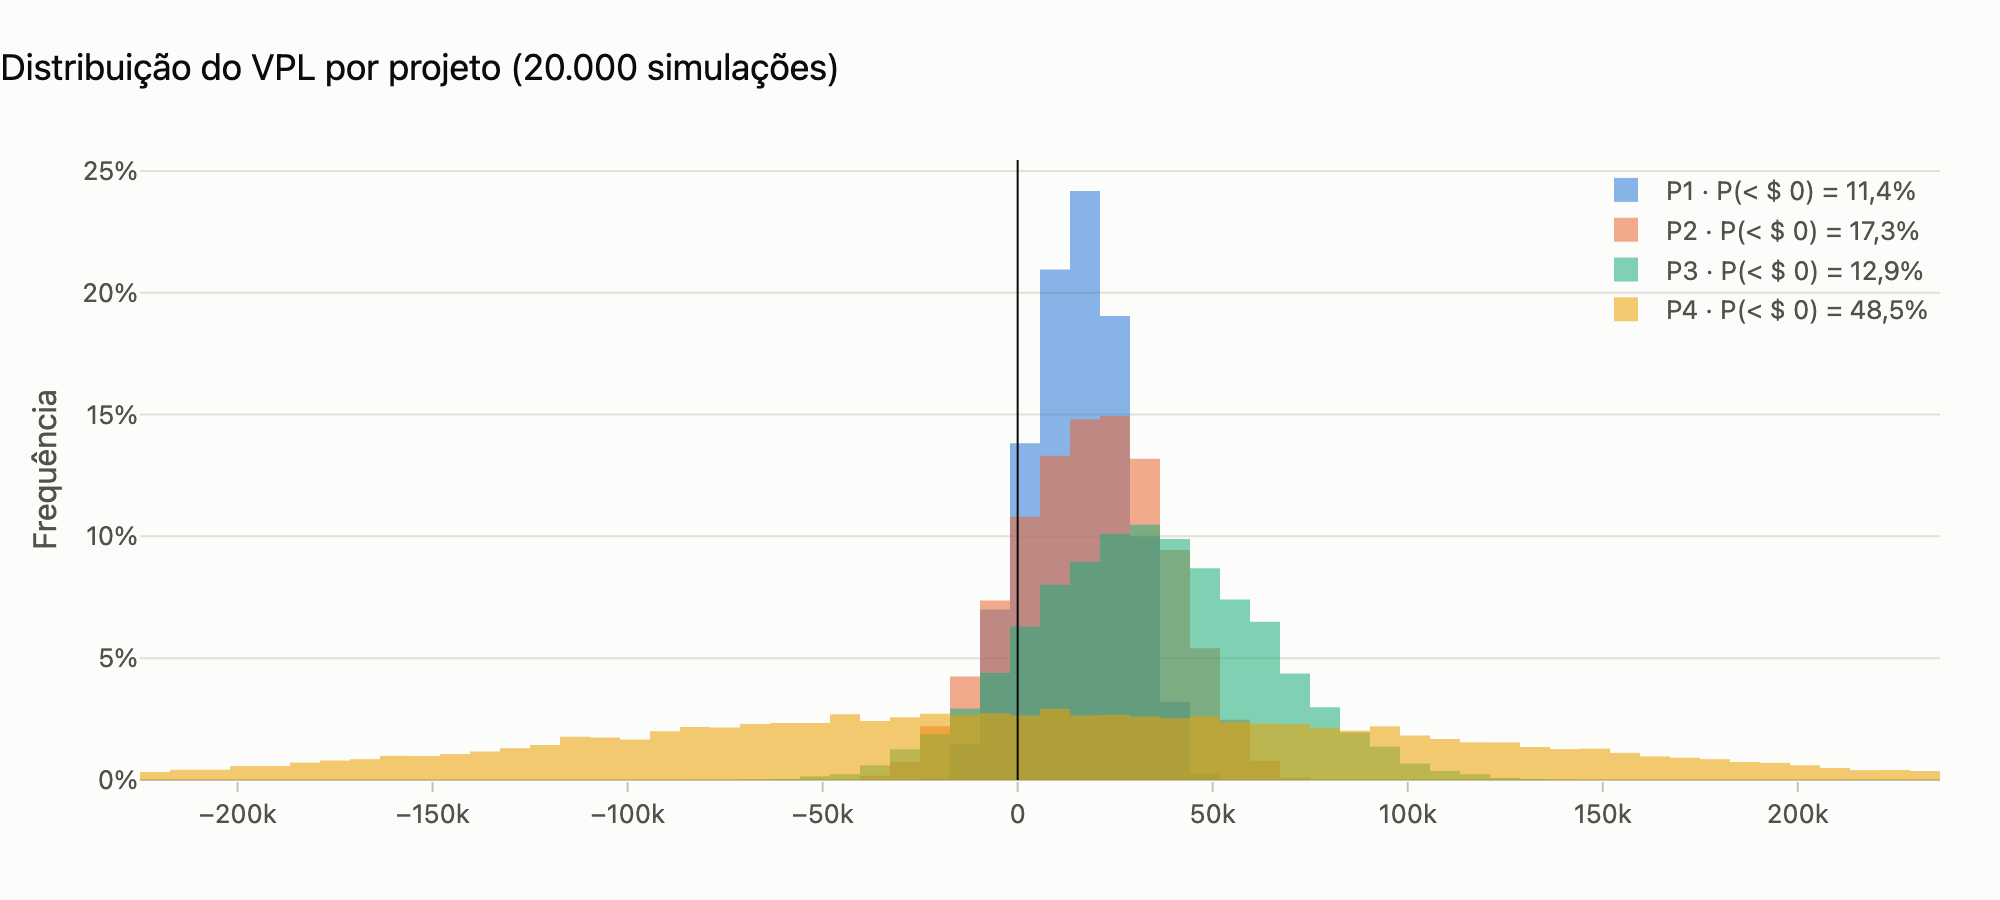

In [6]:
fig = viz.grafico_distribuicoes(res, "vpl", titulo="Distribuição do VPL por projeto (20.000 simulações)")
viz.exportar(fig, f"{SAIDA}/distribuicao_vpl")
fig

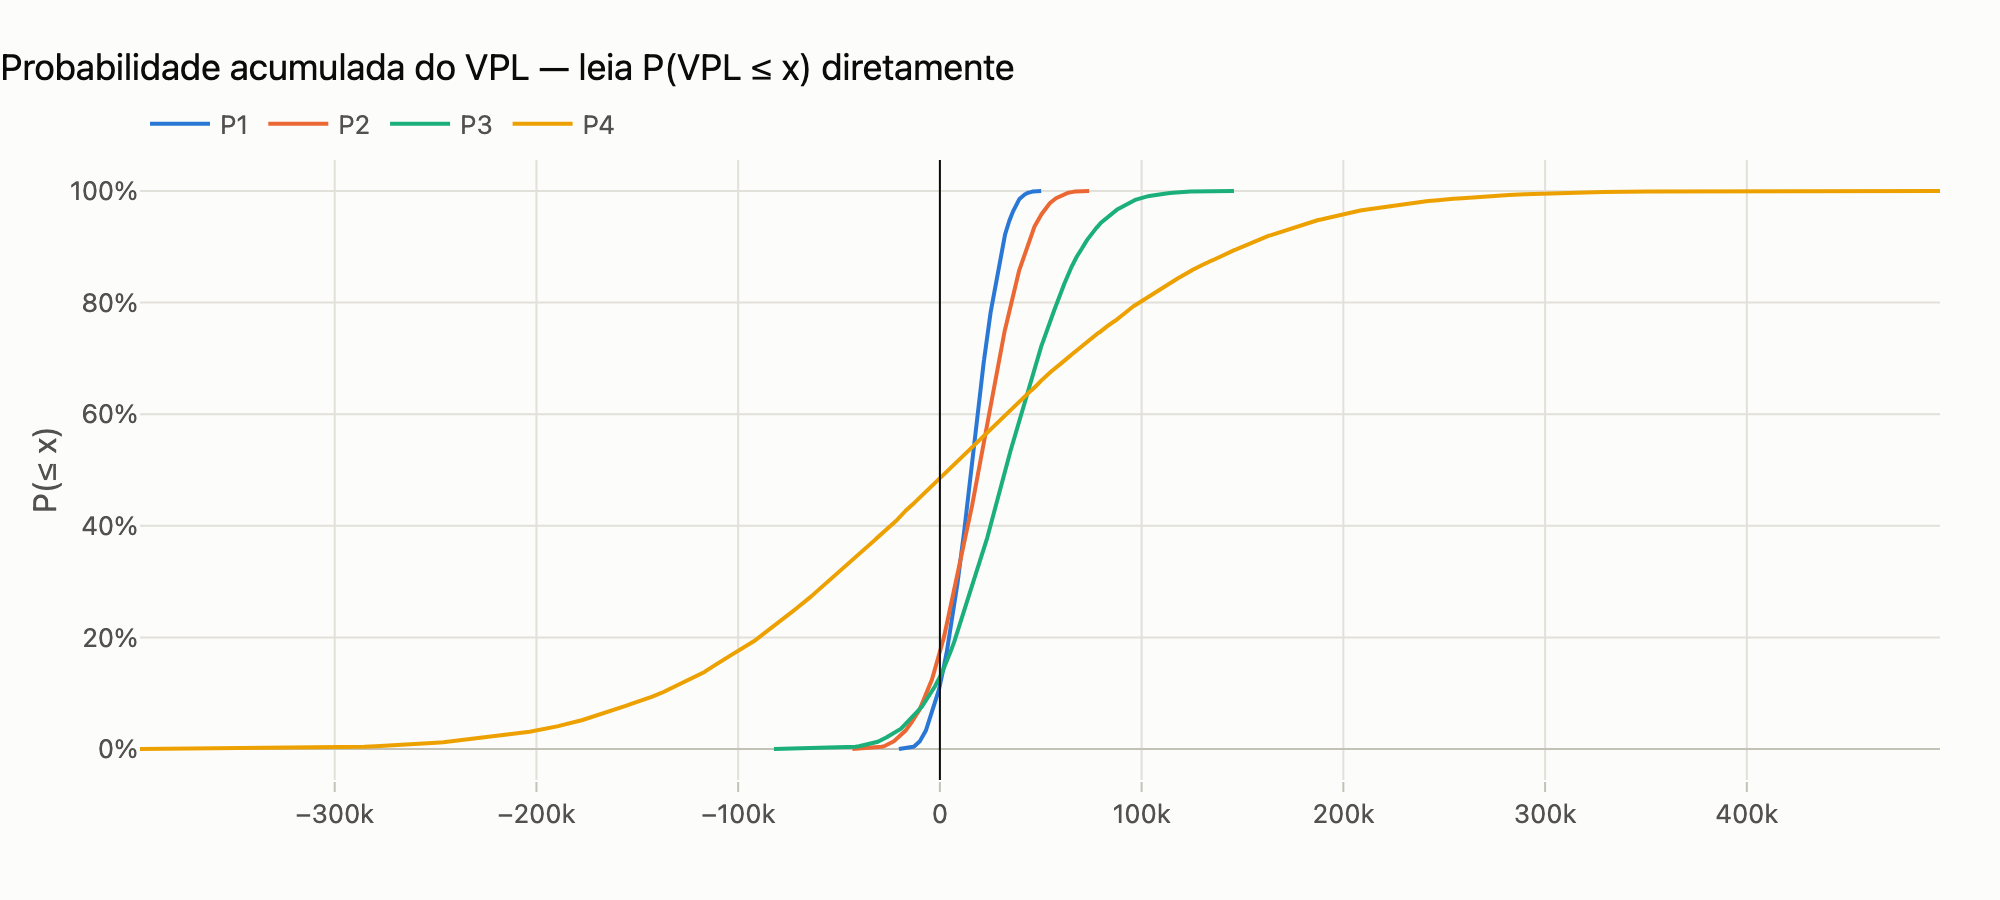

In [7]:
fig = viz.grafico_cdf(res, "vpl", titulo="Probabilidade acumulada do VPL — leia P(VPL ≤ x) diretamente")
viz.exportar(fig, f"{SAIDA}/cdf_vpl")
fig

## 3. Probabilidades para a decisão

In [8]:
probs = pd.DataFrame({
    "P(VPL < 0)": res.probabilidade("vpl", 0.0, "<"),
    "P(TIR < TMA)": res.probabilidade("tir", K, "<"),
    "P(RAU < 0)": res.probabilidade("rau", 0.0, "<"),
    "P(melhor VPL)": res.prob_melhor("vpl"),
    "P(melhor RAU)": res.prob_melhor("rau"),
})
estilizar(probs, tipos={c: "pct" for c in probs.columns}, destacar=["P(VPL < 0)", "P(melhor VPL)", "P(melhor RAU)"], titulo="Probabilidades por projeto")

,P(VPL < 0),P(TIR < TMA),P(RAU < 0),P(melhor VPL),P(melhor RAU)
P1,"11,43%","11,43%","11,43%","8,09%","9,61%"
P2,"17,30%","17,30%","17,30%","16,66%","19,84%"
P3,"12,87%","12,87%","12,87%","38,69%","33,83%"
P4,"48,55%","34,76%","48,55%","36,55%","36,73%"


In [9]:
estilizar(res.prob_superar("vpl"), tipos={c: "pct" for c in res.projetos}, destacar=[], titulo="P(linha tem VPL maior que coluna)")

,P1,P2,P3,P4
Projeto,,,,
P1,—,"43,84%","29,14%","54,07%"
P2,"56,16%",—,"34,73%","55,32%"
P3,"70,86%","65,28%",—,"59,85%"
P4,"45,93%","44,69%","40,15%",—


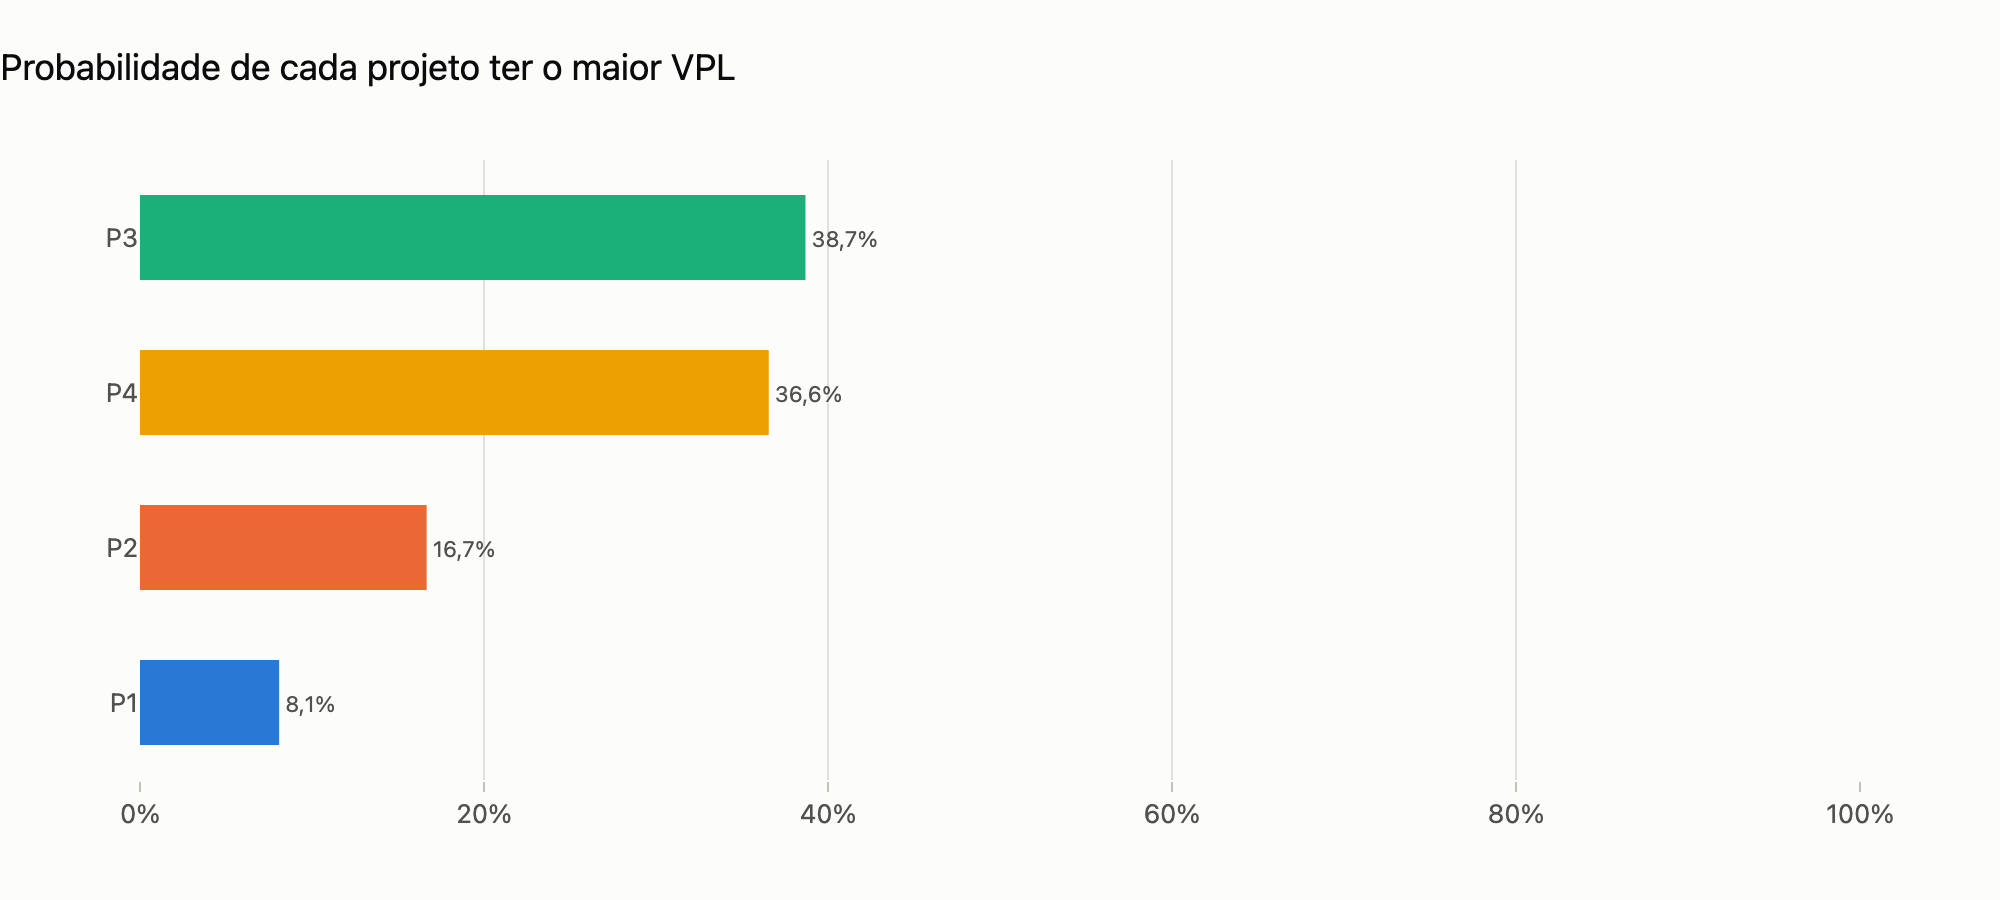

In [10]:
fig = viz.grafico_prob_melhor(res.prob_melhor("vpl"), titulo="Probabilidade de cada projeto ter o maior VPL")
viz.exportar(fig, f"{SAIDA}/prob_melhor")
fig

## 4. O que move o resultado (tornado por correlação)

A correlação de Spearman entre cada premissa sorteada e o VPL mostra quais incertezas realmente importam —
é a versão probabilística do tornado do notebook 3.

In [11]:
sens = res.sensibilidade(metrica="vpl").rename(index=ROTULOS)
estilizar_divergente(sens, amplitude=1.0, titulo="Correlação (Spearman) entre premissas e VPL")

,P1,P2,P3,P4
Parâmetro,,,,
P1 · unidades/ano,+0.92,-0.01,+0.00,+0.19
P1 · custo variável unit.,-0.36,+0.00,-0.00,+0.01
P2 · fator sobre as receitas,-0.00,+0.54,+0.01,-0.01
P2 · CPV (% da receita),+0.00,-0.82,-0.00,+0.00
P3 · crescimento anual,-0.00,+0.02,+0.36,-0.00
P3 · CPV (± p.p.),-0.00,-0.00,-0.92,-0.01
P3 · valor residual,+0.01,+0.00,+0.04,-0.00
P4 · unidades no ano 1,+0.44,-0.01,-0.00,+0.38
P4 · preço no ano 1,+0.01,-0.00,+0.01,+0.84


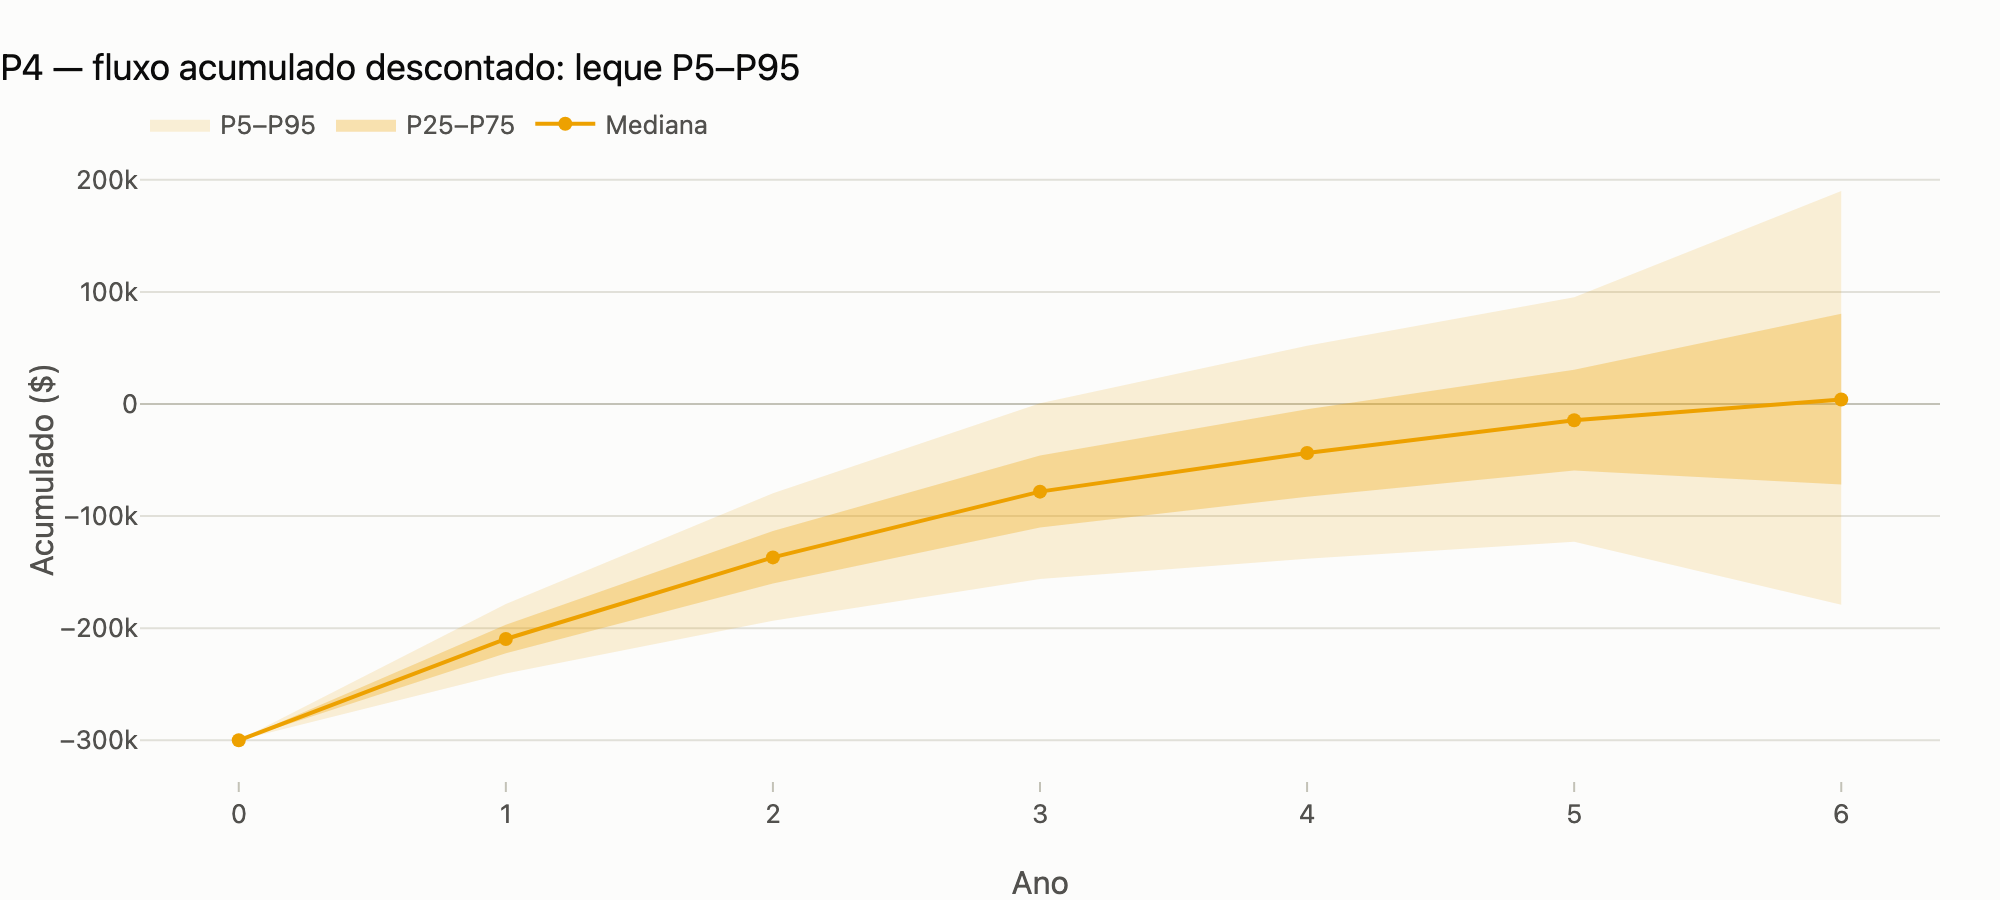

In [12]:
fig = viz.grafico_leque(res, "P4", titulo="P4 — fluxo acumulado descontado: leque P5–P95")
viz.exportar(fig, f"{SAIDA}/leque_p4")
fig

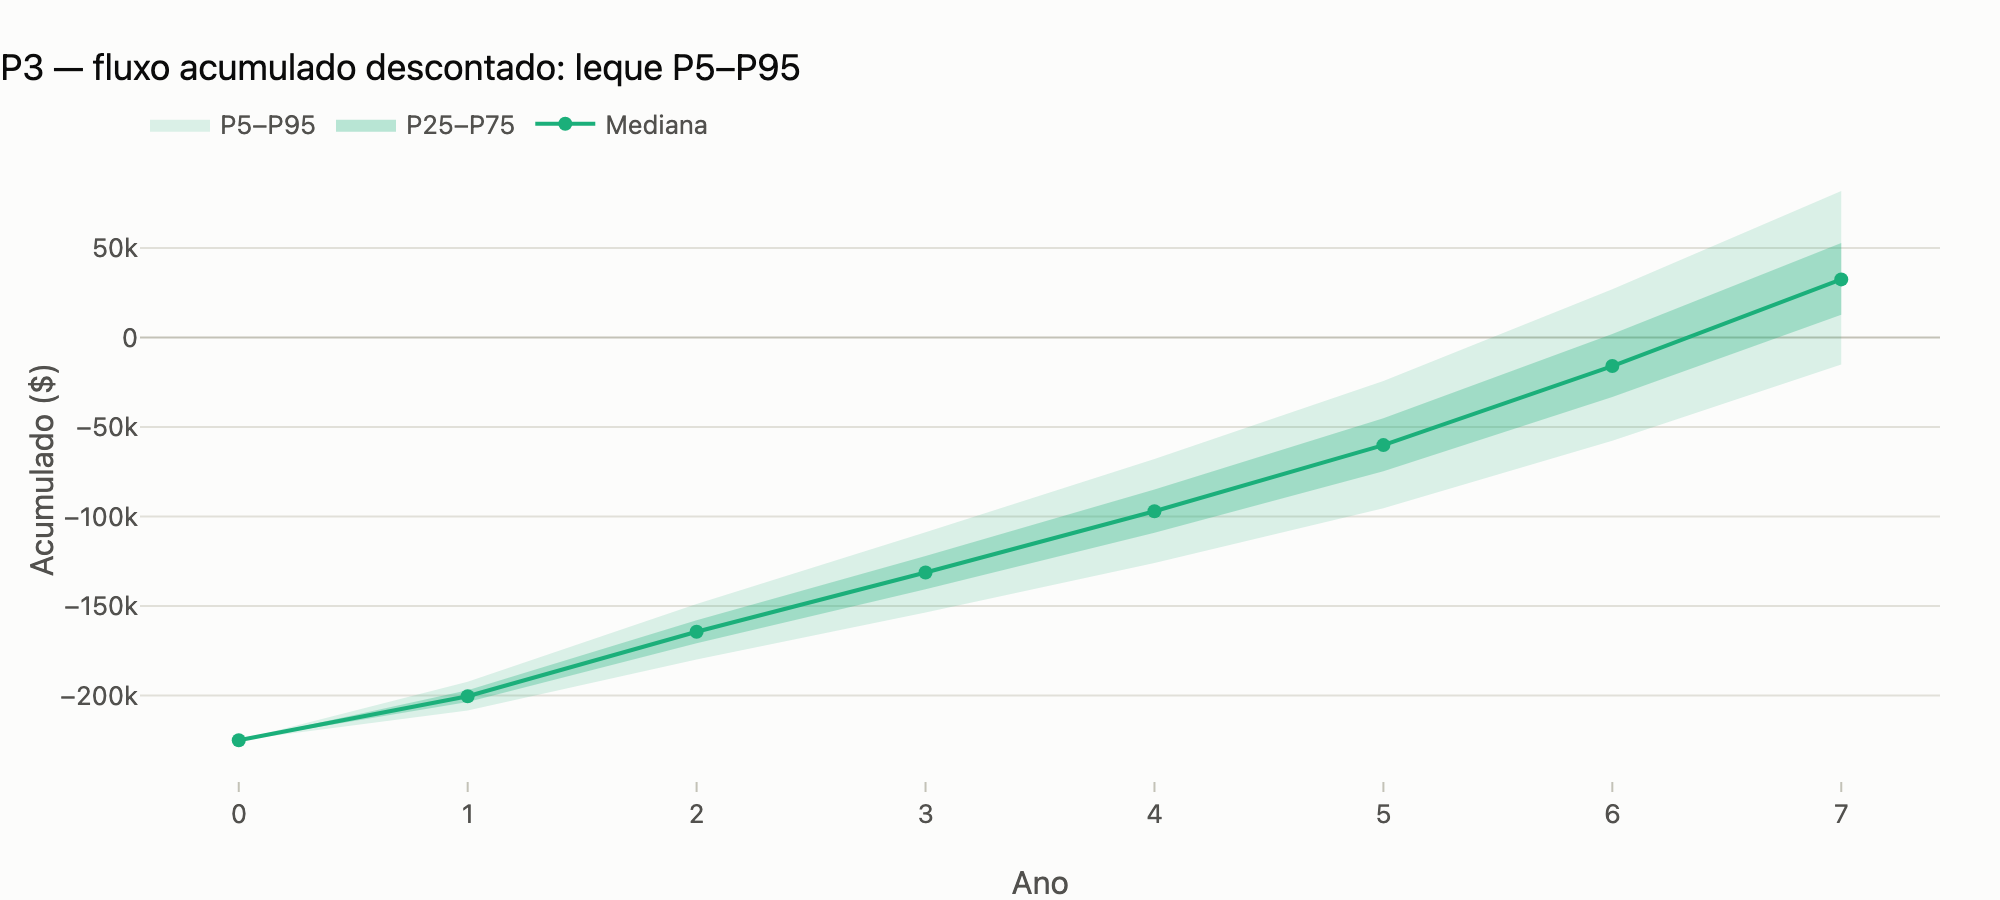

In [13]:
fig = viz.grafico_leque(res, "P3", titulo="P3 — fluxo acumulado descontado: leque P5–P95")
viz.exportar(fig, f"{SAIDA}/leque_p3")
fig

## 5. Carteiras de dois projetos

Somando o VPL simulado de cada par (os projetos são independentes, mas as premissas podem ser correlacionadas)
obtemos a distribuição do VPL de cada carteira.

In [14]:
cart, dist_cart = res.carteiras(k=2)
estilizar(cart, tipos={"Nº projetos": "int"}, titulo="Carteiras de dois projetos — VPL simulado")

,Nº projetos,Investimento,Média,Desvio padrão,CV,Mínimo,P5,Mediana,P95,Máximo,P(< 0),CVaR 5%,n válidas,P(melhor)
Carteira,,,,,,,,,,,,,,
P2 + P3,2,$ 425.000,$ 51.596,$ 35.131,"0,68",($ 77.345),($ 6.173),$ 51.682,$ 108.859,$ 189.192,"7,13%",($ 20.004),20000,"26,16%"
P1 + P3,2,$ 425.000,$ 48.217,$ 31.772,"0,66",($ 85.236),($ 3.878),$ 47.853,$ 101.068,$ 169.692,"6,33%",($ 16.246),20000,"18,23%"
P3 + P4,2,$ 525.000,$ 37.461,$ 116.231,"3,10",($ 376.400),($ 152.239),$ 36.895,$ 230.313,$ 530.075,"37,52%",($ 201.144),20000,"24,80%"
P1 + P2,2,$ 400.000,$ 33.952,$ 22.296,"0,66",($ 47.188),($ 3.957),$ 34.435,$ 69.753,$ 103.157,"7,00%",($ 12.216),20000,"11,49%"
P2 + P4,2,$ 500.000,$ 23.196,$ 113.678,"4,90",($ 372.512),($ 162.755),$ 22.570,$ 209.638,$ 505.761,"42,08%",($ 209.837),20000,"10,99%"
P1 + P4,2,$ 500.000,$ 19.817,$ 115.006,"5,80",($ 402.441),($ 167.766),$ 19.132,$ 210.108,$ 528.868,"43,43%",($ 215.653),20000,"8,32%"


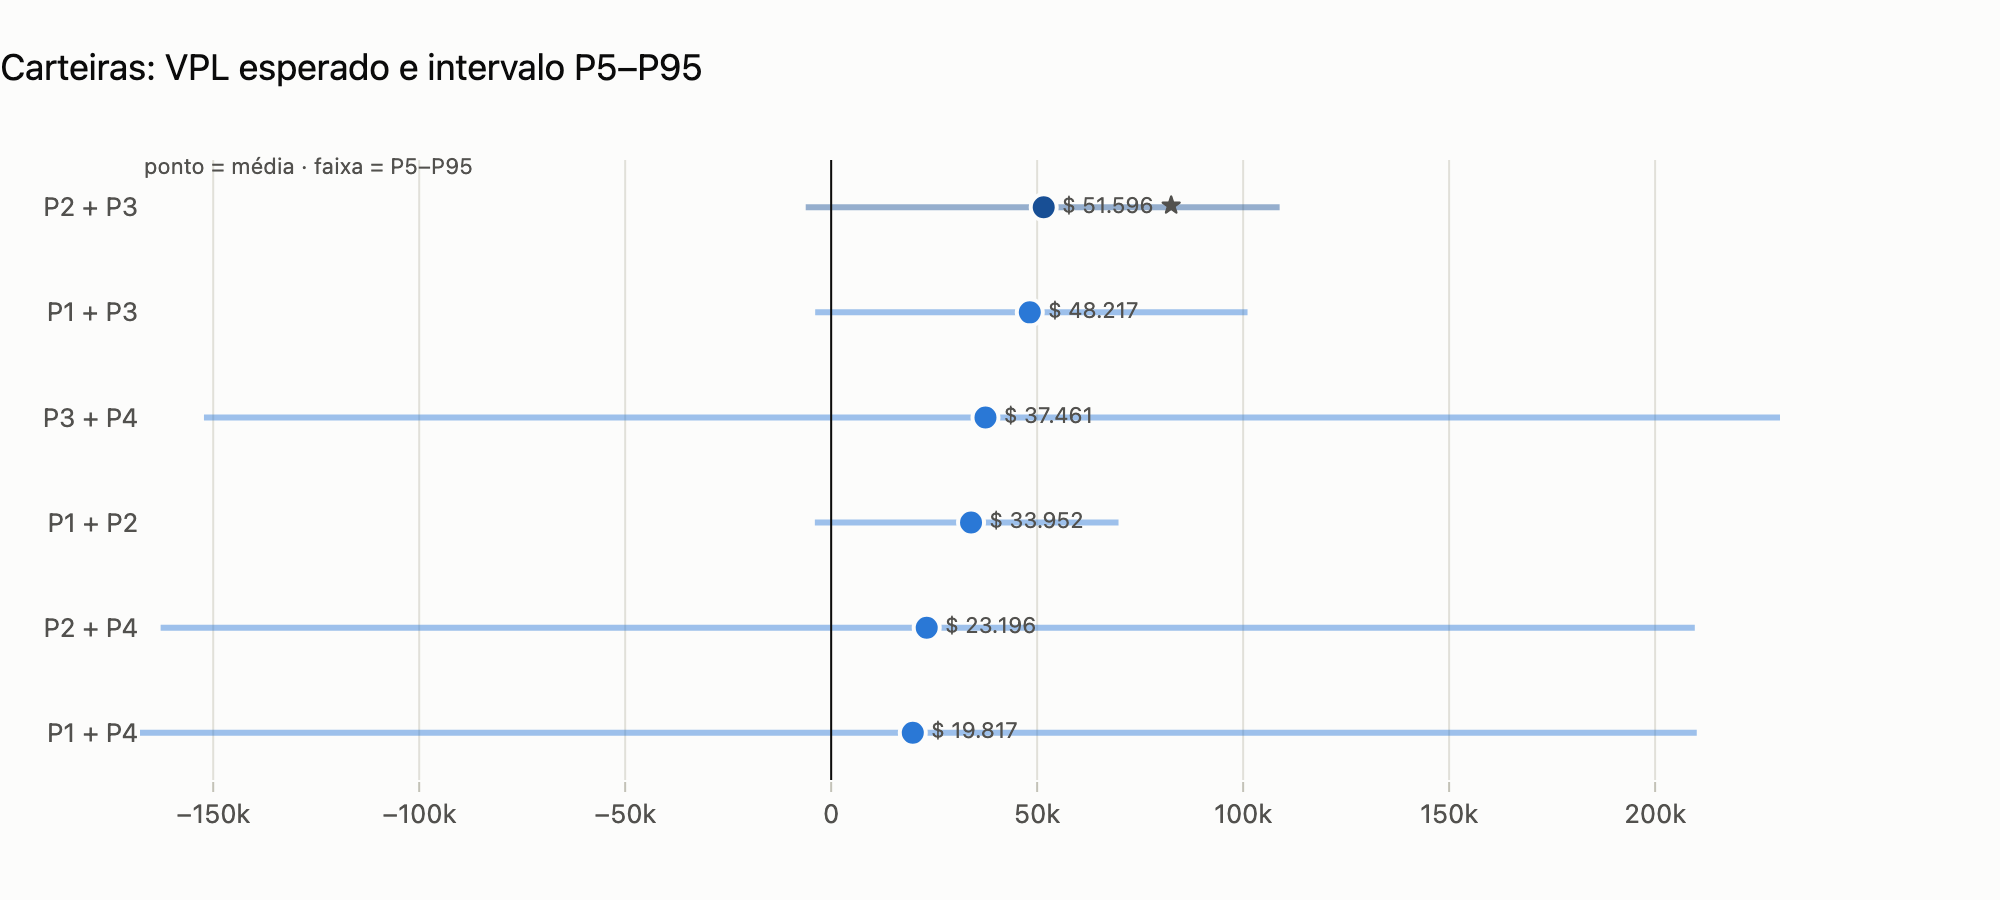

In [15]:
fig = viz.grafico_carteiras(cart, coluna="Média", faixa=("P5", "P95"), titulo="Carteiras: VPL esperado e intervalo P5–P95")
viz.exportar(fig, f"{SAIDA}/carteiras")
fig

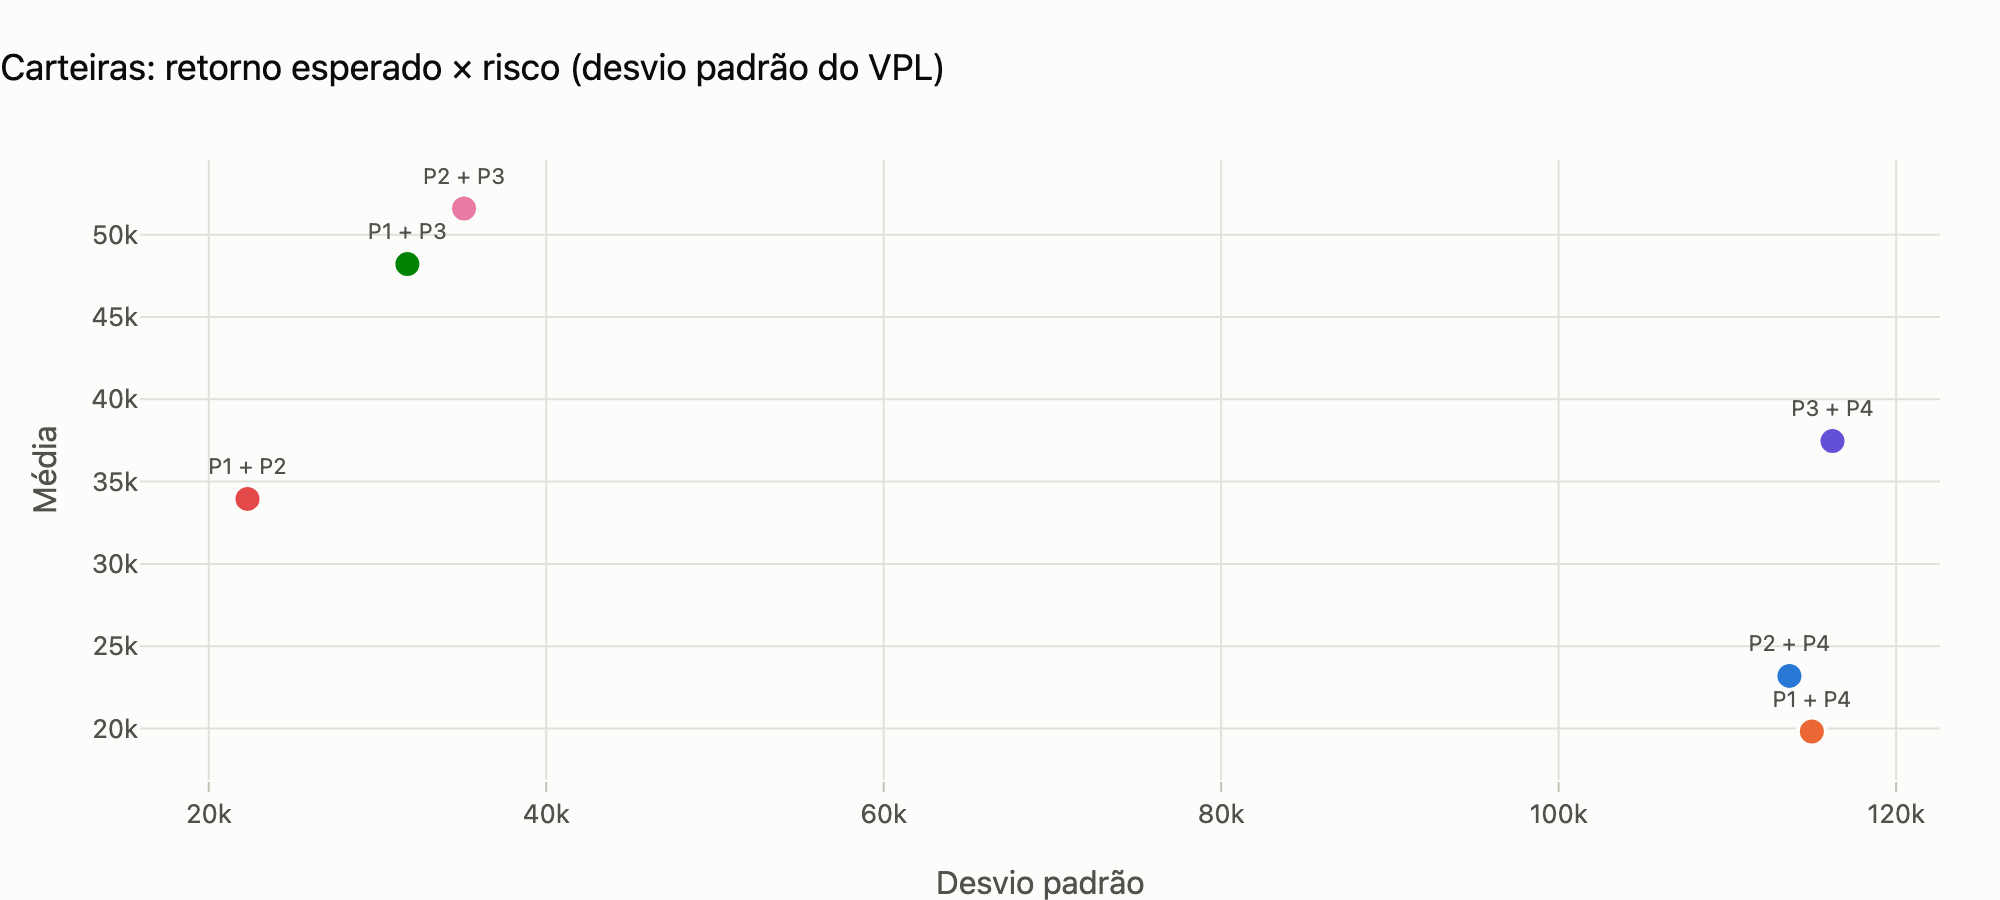

In [16]:
fig = viz.grafico_risco_retorno(cart, x="Desvio padrão", y="Média", titulo="Carteiras: retorno esperado × risco (desvio padrão do VPL)")
viz.exportar(fig, f"{SAIDA}/carteiras_risco_retorno")
fig

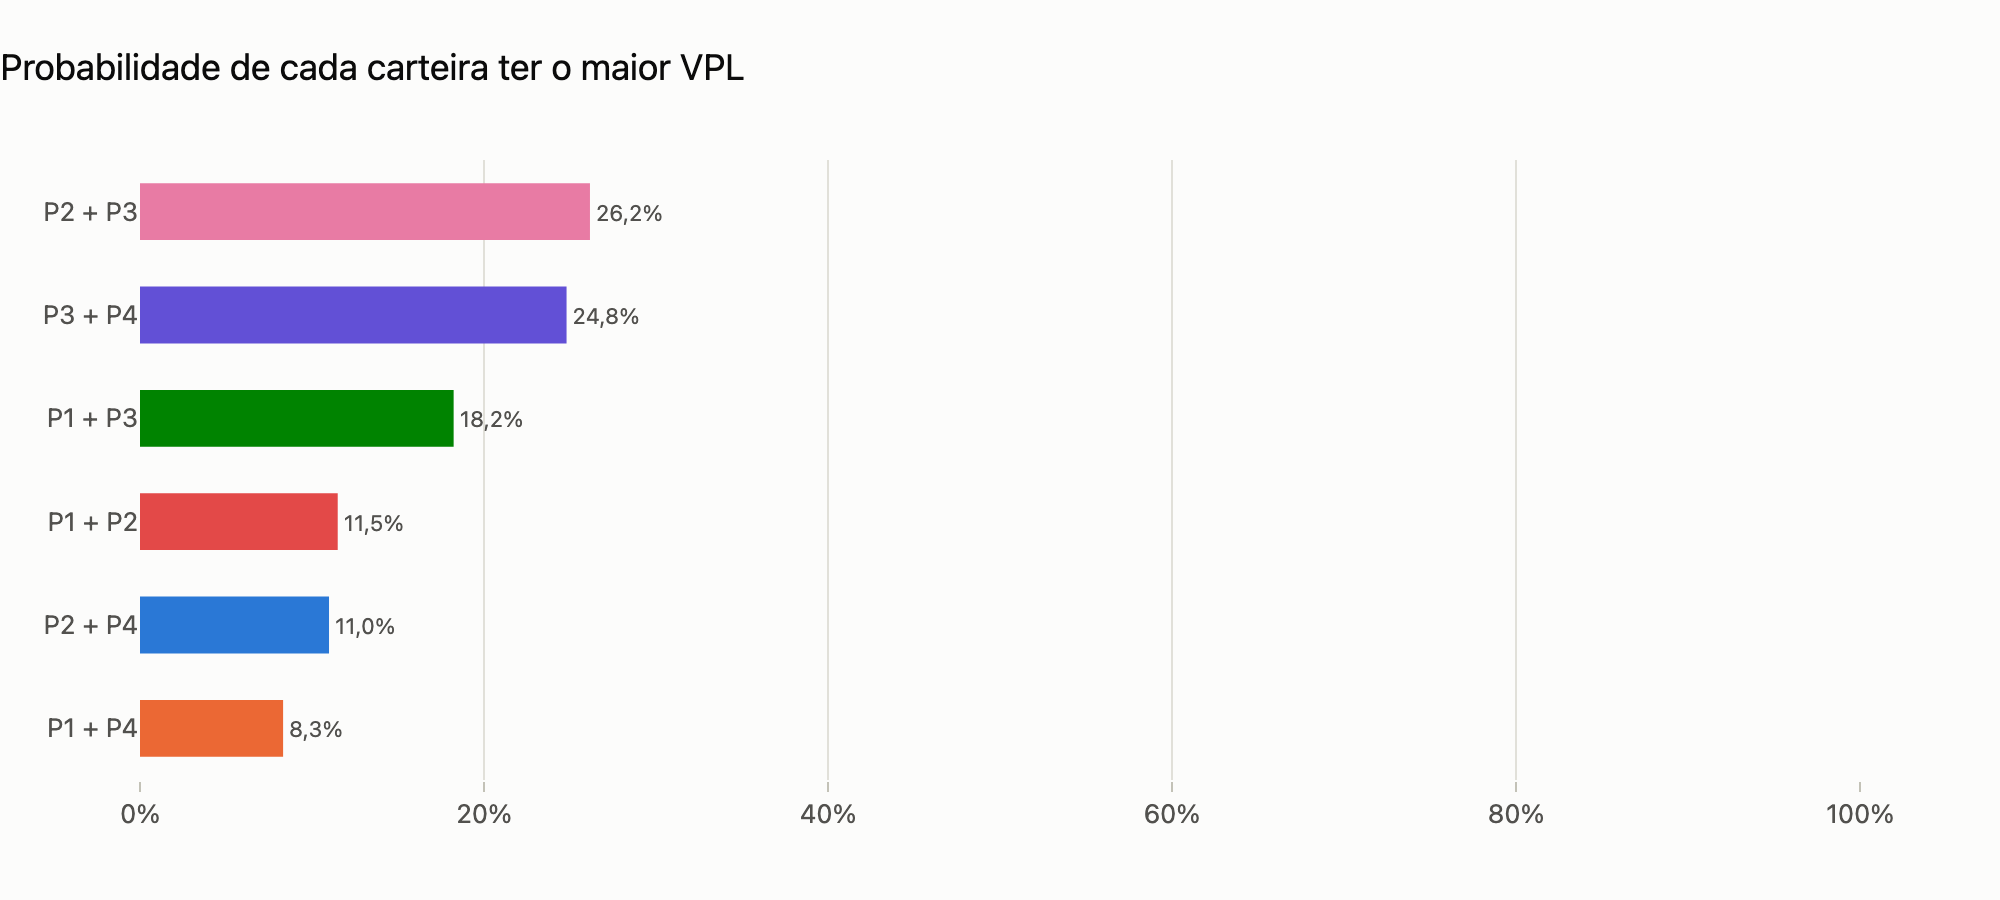

In [17]:
fig = viz.grafico_prob_melhor(cart["P(melhor)"], titulo="Probabilidade de cada carteira ter o maior VPL")
viz.exportar(fig, f"{SAIDA}/carteiras_prob_melhor")
fig

## 6. Parecer para o board

| Pergunta | Caso-base (notebook 2) | Com risco (cenários + Monte Carlo) |
|---|---|---|
| Melhor projeto isolado | P4 (maior VPL e RAU) | **P3**: maior VPL esperado, ~13% de chance de VPL negativo; P4 tem ~50% |
| Dois melhores | P4 + P3 (VPL) ou P4 + P2 (RAU) | **P2 + P3**: maior VPL esperado, maior chance de ser a melhor carteira (26%) e só 7% de chance de perda |
| Projeto a evitar | P1 (menor VPL) | P4, a menos que preço e volume sejam contratados: ponto de equilíbrio a 1,8% de queda de preço |

**Mensagens-chave**

1. O ranking determinístico esconde que P4 é uma aposta alavancada: custo fixo alto e margem fina fazem o
   VPL variar de −$400 mil a +$500 mil, com quase 50% de chance de ser negativo.
2. P3 e P2 têm distribuições concentradas; juntos formam a carteira de maior VPL esperado, e P1 + P3 é a
   alternativa de menor risco com retorno quase igual.
3. Se o board quiser P4, a decisão deve vir acompanhada de mitigação (contratos de preço/volume, redução de
   custo fixo) — a simulação permite recalcular a probabilidade de perda com essas medidas.

Todos os gráficos deste notebook foram exportados para `outputs/04/` em HTML interativo e PNG para a apresentação.